### Alfabeto Original (sem ruído) ###


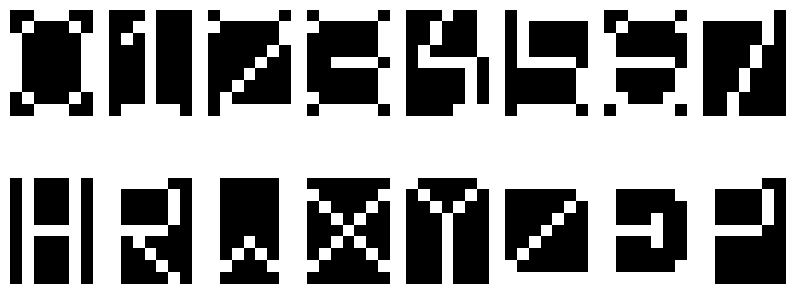


### Alfabeto com 30% de Ruído ###


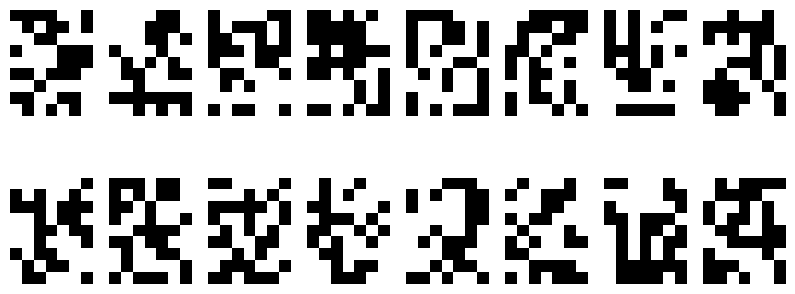

In [ ]:
#Funcao apenas para visualizar os caracteres e para poder gerar o alfabeto (0, 1, 2, 3, 4, 5, 6, 7, H, R, W, X, Y, Z, F, P)
import geraChar

(P_original, T) = geraChar.geraChar()

print("### Alfabeto Original (sem ruído) ###")
geraChar.showChar(P_original)

Pn_ruidoso = geraChar.gchar_ruido(P_original, 50)

print("\n### Alfabeto com 30% de Ruído ###")
geraChar.showChar(Pn_ruidoso)

In [3]:
# ANN OCR trained with Noise
# numpy/tensorflow/keras
#
# IC/UnB Ex1 - Oct/2024 - Adolfo Bauchspiess

# python < 3.120 for TensorFlow with GPU

import numpy as np


from tensorflow.keras.models import Sequential, clone_model
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import plot_model


import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.cm as cm
import matplotlib.lines as lines

import tensorflow as tf

import geraChar


N=   6 # Levels of noise
Nnt=  10 # Number of training noise samples for each noise level
Nnv= 10 # Number of validating noise samples
NStep= 10 # Noise step

P=[]  # Pattern
T=[]  # Target
Pn=[] # Noise Pattern
fitT=np.zeros((N),dtype=int)  # Store the number of incorrect Chars while training
fitV=np.zeros((N),dtype=int)  # Store the number of incorrect Chars while training


In [4]:
# create models with 0, 10, 20 .... 90% noisy bit
(P,T)=geraChar.geraChar()

# Creat a set of N ANNs
Models=[]
for i in range(N): # for each model
    model = Sequential()
    model.add(Dense(30, activation="sigmoid", kernel_initializer="uniform", input_dim=63))
    model.add(Dense(16, activation="sigmoid", kernel_initializer="uniform"))
    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
    Models.append(model)

print("Train networks")
Models[0].fit(P, T, epochs=800, batch_size=1, verbose=0)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Train networks


In [5]:

for i in range(1,N): # for each model
# Learn Nstep epochs Noise Chars + epochs reforcing orig. Chars.

    # Mantain Models[i-1] and proceed training with noise
    Models[i].set_weights(Models[i-1].get_weights())

    # test with different noise levels (at least once - range(i+1))
    for k in range(Nnt):
        Pn = geraChar.gchar_ruido(P,NStep*i)
        Models[i].fit(Pn, T, epochs=10, batch_size=1, verbose=0)
        (incorr,idx) = geraChar.validacao(Pn,Models[i])
        fitT[i] += incorr

    #Pn = geraChar.gchar_ruido(P,0) # Reforce learning without noise
    Models[i].fit(P, T, epochs=10, batch_size=1, verbose=0)
    (incorr,idx) = geraChar.validacao(P,Models[i])
    fitT[i] += incorr

    print("Rede i",i,"incorr",str(np.round(fitT[i],2)))


Rede i 1 incorr 0
Rede i 2 incorr 1
Rede i 3 incorr 16
Rede i 4 incorr 90
Rede i 5 incorr 151


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 30)             │         1,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 16)             │           496 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,250 (28.32 KB)

 Trainable params: 2,416 (9.44 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4,834 (18.89 KB)

None


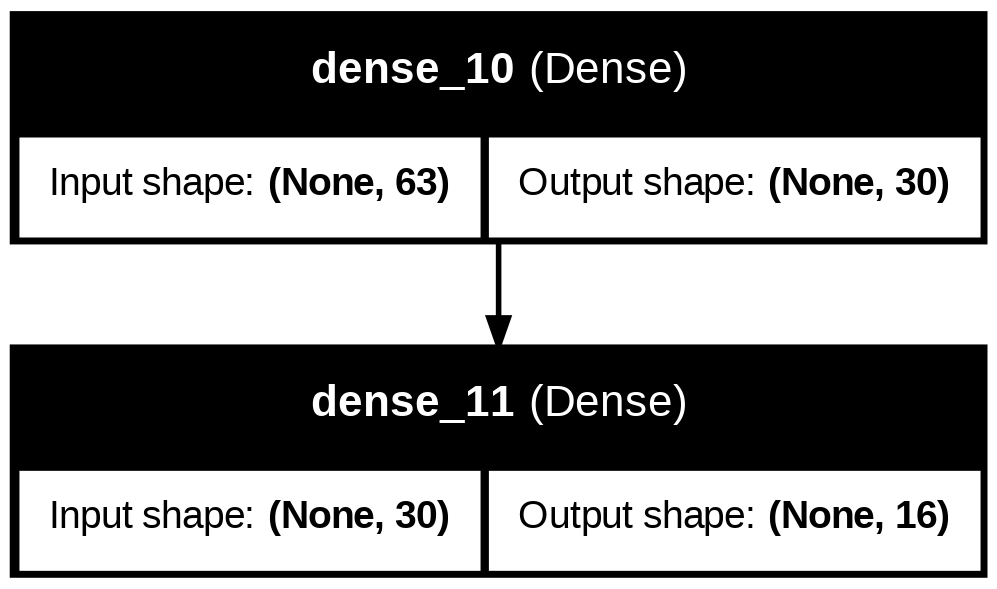

In [6]:
print(model.summary())
plot_model(model, to_file='model.png',show_shapes=True, show_layer_names=True)

In [7]:
# Validate the trained ANN

fitV=np.zeros((N),dtype=float)
for i in range(N): # for each model
    for k in range(Nnv):
        Pn = geraChar.gchar_ruido(P,NStep*i)
        (incorr,idx) = geraChar.validacao(Pn,Models[i])
        fitV[i] += incorr
FitV=np.round(100*fitV/(16*Nnv),2)
print("Test ANN trained with 0%, 10%,...  noise. % incorrect Chars = ",FitV)

fitO=np.zeros((N),dtype=float)
for i in range(N): # for each model
    for k in range(Nnv):
        Pn = geraChar.gchar_ruido(P,NStep*i)
        (incorr,idx) = geraChar.validacao(Pn,Models[0])
        fitO[i] += incorr
FitO=np.round(100*fitO/(16*Nnv),2)
print("Test original (no noisy train) % incorrect Chars = ",FitO)



Test ANN trained with 0%, 10%,...  noise. % incorrect Chars =  [ 0.    0.    1.88 23.75 72.5  95.  ]
Test original (no noisy train) % incorrect Chars =  [ 0.    0.    5.   36.88 84.38 96.25]


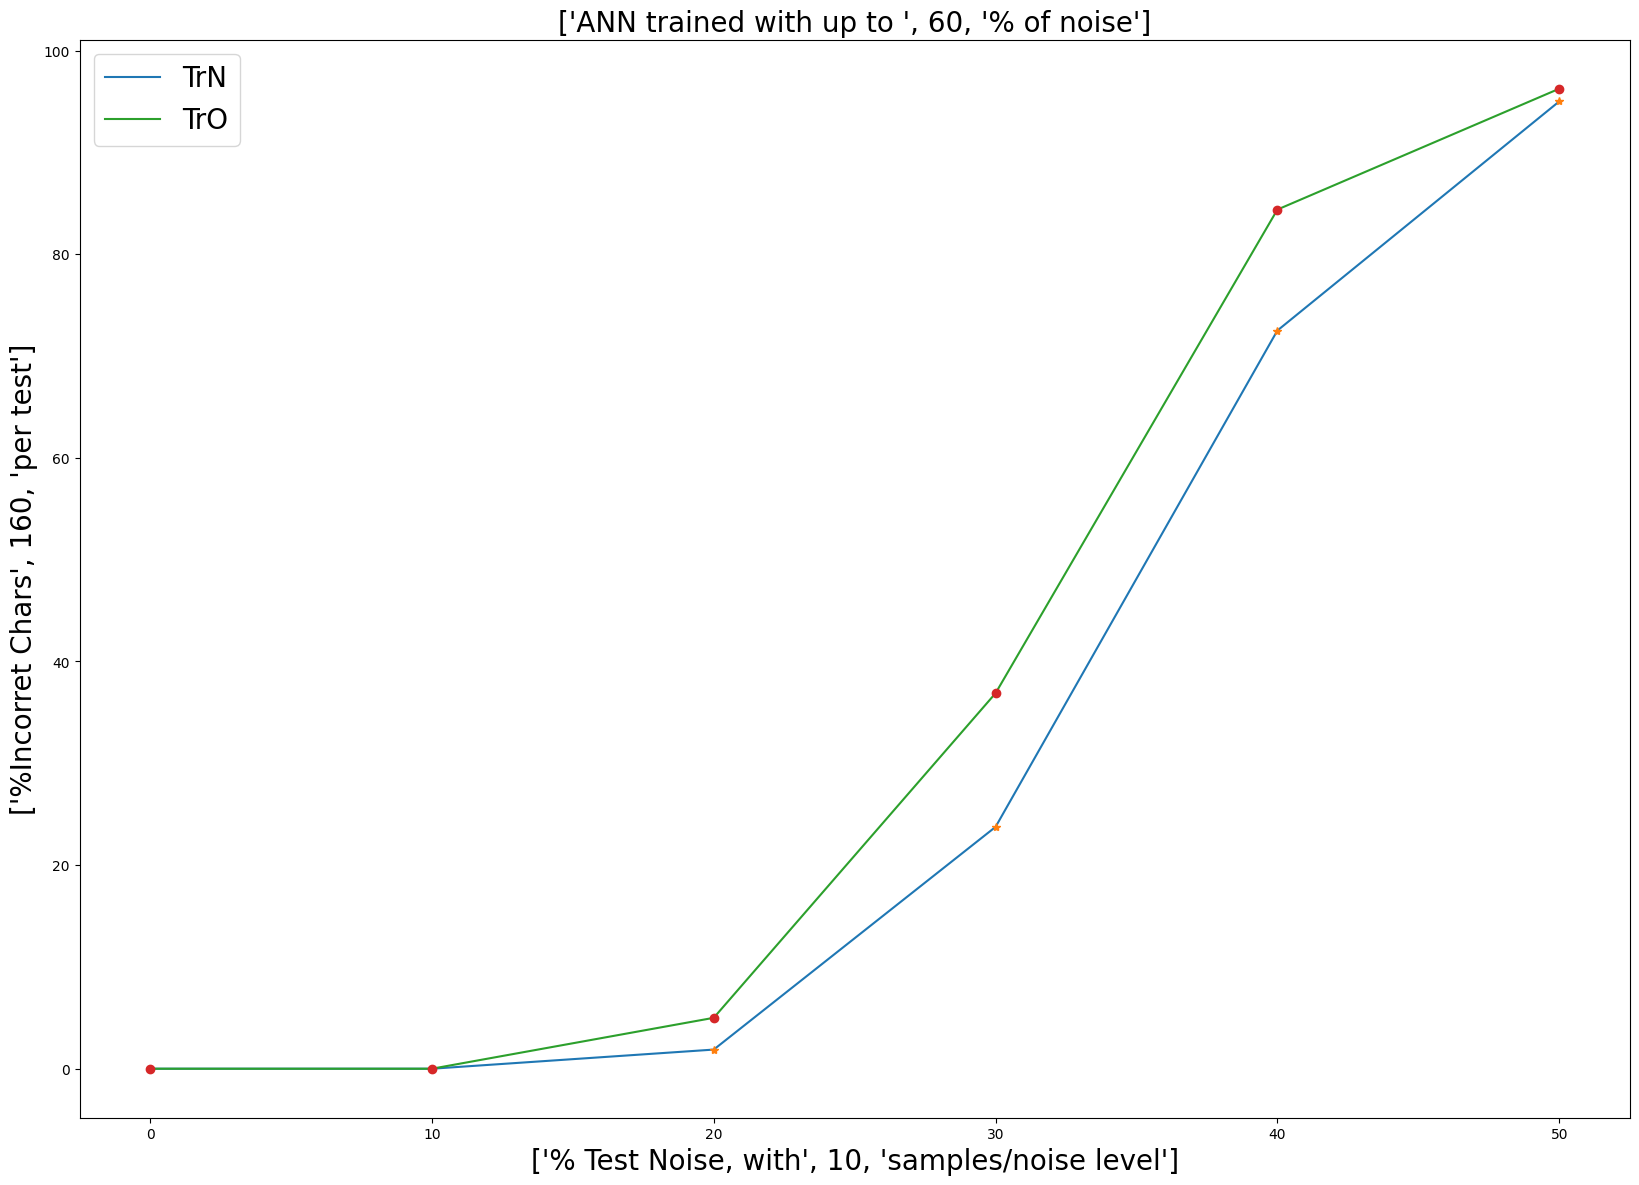

In [8]:
plt.figure(figsize=(20,14))

plt.plot(range(0,NStep*N,NStep),FitV, label=['TrN'])
plt.plot(range(0,NStep*N,NStep),FitV,'*')

plt.plot(range(0,NStep*N,NStep),FitO, label=['TrO'])
plt.plot(range(0,NStep*N,NStep),FitO,'o')

plt.title(['ANN trained with up to ' ,N*Nnv,'% of noise'], fontsize=20)
plt.ylabel(["%Incorret Chars",Nnv*16,'per test'], fontsize=20)
plt.xlabel(['% Test Noise, with',Nnv,'samples/noise level'], fontsize=20)
plt.legend(loc='upper left', fontsize=20)

plt.savefig('figANN.pdf')
plt.show()